# Using genomic-benchmarks-data4agents

This tutorial demonstrates dataset discovery, metadata, loading, caching, and quality-control (QC) results with the agent-safe package. It exposes `train` and `val` data where available, but never `test` data or `test`-related QC.

You will learn how to:

- discover collections, datasets, and the benchmark core set;
- present dictionary results in a human-readable form;
- inspect available filter values and metadata;
- load data and locate cached files; and
- explore QC results, summaries, and self-contained reports.

Install the package if it is not already available in this environment:

```python
%pip install genomic-benchmarks-data4agents
```

In [ ]:
from IPython.display import display
import pandas as pd
import genomic_benchmarks_data4agents as gbd

from utils import display_qc_report

## Discover datasets

Package discovery functions return ordinary Python dictionaries that can be used directly in code. The next cell shows the raw result first, followed by the same dictionary rendered with `pretty()` for easier reading.

In [2]:
collections = gbd.list_collections()
display(collections)
gbd.pretty(collections)


{'BEACON': 'https://doi.org/10.52202/079017-2949',
 'GUE_v2': 'https://doi.org/10.48550/arXiv.2306.15006',
 'OmniGenBench': 'https://doi.org/10.48550/arXiv.2505.14402',
 'genomic-benchmarks': 'https://doi.org/10.1186/s12863-023-01123-8',
 'mRNABench': 'https://doi.org/10.1101/2025.07.05.662870',
 'miRBench': 'https://doi.org/10.1093/bioinformatics/btaf233',
 'nucleotide_benchmarks': 'https://doi.org/10.1038/s41592-024-02523-z'}

BEACON,https://doi.org/10.52202/079017-2949
GUE_v2,https://doi.org/10.48550/arXiv.2306.15006
OmniGenBench,https://doi.org/10.48550/arXiv.2505.14402
genomic-benchmarks,https://doi.org/10.1186/s12863-023-01123-8
mRNABench,https://doi.org/10.1101/2025.07.05.662870
miRBench,https://doi.org/10.1093/bioinformatics/btaf233
nucleotide_benchmarks,https://doi.org/10.1038/s41592-024-02523-z


### Select the core set

The core set is a selected subset of benchmarks. Pass `core_set=True` to select it, or `core_set=False` to select its complement. Core-set selection can be combined with the other dataset filters.

In [3]:
core_datasets = gbd.list_datasets(core_set=True)
gbd.pretty(core_datasets)


{'BEACON': {'CRISPROnTarget': 'Prediction of the knockout efficacy of single-guide RNA '
                              '(sgRNA) directed by Cas proteins in gene editing within '
                              'specific target sites.'},
 'GUE_v2': {'transcription_factor_prediction_mouse_4': 'Prediction of transcription '
                                                       'factor binding sites (mouse, '
                                                       'subset 4)',
            'epigenetic_marks_prediction_H3K4me3': 'Prediction of epigenetic marks '
                                                   '(H3K4me3 histone modifications) in '
                                                   'yeast'},
 'OmniGenBench': {'pro_seq_m_esculenta': 'Prediction of enhancer elements in Manihot '
                                         'esculenta seedlings (plant)',
                  'promoter_strength_protoplast': 'Prediction of promoter strength in '
                                                  'protoplasts (plant)'},
 'genomic-benchmarks': {'drosophila_enhancers_stark': 'Prediction of enhancers'},
 'mRNABench': {'translation-efficiency-human': 'Prediction of translation efficiency '
                                               'from sequence.',
               'rnahl-human': 'Prediction of mRNA half-life from sequence. Target is '
                              'first PCA component of half-life measurments across 39 '
                              'human aggregated datasets. '},
 'miRBench': {'AGO2_eCLIP_Manakov2022': 'Prediction of miRNA binding site'}}

This tutorial uses the small core-set dataset `BEACON/CRISPROnTarget`, which provides `train` and `val` data. Change the two values in the next cell to explore another dataset.

In [4]:
COLLECTION = "BEACON"
DATASET = "CRISPROnTarget"

### Explore available filter values

`list_dataset_filters()` shows the filters accepted by `list_datasets()` and their currently available values. Passing `COLLECTION` limits the metadata-derived values to the selected collection; omit it to inspect values across the entire package.

In [5]:
filter_values = gbd.list_dataset_filters(COLLECTION)
gbd.pretty(filter_values)


collection,BEACON
molecular_level,DNARNA
task_category,Engineering PredictionRNA Processing PredictionTranslation Efficiency Prediction
task_type,Regression
species,Homo sapiens
core_set,TrueFalse


## Inspect metadata

Use the targeted accessors for ordinary exploration. `load_metadata()` is also available when the complete packaged metadata is needed for bulk processing.

In [6]:
dataset_info = gbd.get_dataset_info(COLLECTION, DATASET)
split_info = {
    split: gbd.get_split_info(COLLECTION, DATASET, split)
    for split in dataset_info["splits"]
}

display(gbd.pretty(dataset_info))
gbd.pretty(split_info)


dataset_name,CRISPROnTarget
task_description,Prediction of the knockout efficacy of single-guide RNA (sgRNA) directed by Cas proteins in gene editing within specific target sites.
dataset_doi,https://doi.org/10.1186/s13059-018-1459-4
species,Homo sapiens
task_type,Regression
seq_col,seq
label_col,label
label_categories,None
splits,trainval
major_version,v1
task_category,Engineering Prediction


{'train': {'seq_length': {'seq': {'min': 23, 'max': 23, 'median': 23}},
           'seq_alphabet': {'seq': ['A', 'C', 'G', 'T']},
           'labels': {'min': 0.0277828845416346,
                      'max': 0.692699498961697,
                      'median': 0.216143386109033},
           'dataset_size': 1453,
           'class_ratio': None,
           'all_columns': ['id', 'row_index', 'seq', 'label'],
           'sha256': '66cf1af39463cfb3acb9aca56c13fde6e2c31cd170470e874e761d52d6e19db5'},
 'val': {'seq_length': {'seq': {'min': 23, 'max': 23, 'median': 23}},
         'seq_alphabet': {'seq': ['A', 'C', 'G', 'T']},
         'labels': {'min': 0.0282258939460234,
                    'max': 0.55142413846013,
                    'median': 0.216666917873199},
         'dataset_size': 207,
         'class_ratio': None,
         'all_columns': ['id', 'row_index', 'seq', 'label'],
         'sha256': '0e21e3f7b58487289173c8b1ee692175ee661cd85528c44ff84a200b06ab1549'}}

Only the splits listed above are accessible. `test` and `test_leftout` files and their metadata are not included in this package.

## Load `train` and `val` data

By default, `load_dataset()` returns the sequence and label columns.

In [7]:
train = gbd.load_dataset(COLLECTION, DATASET, "train")
validation = gbd.load_dataset(COLLECTION, DATASET, "val")

loaded_splits = pd.DataFrame(
    [
        {
            "split": "train",
            "rows": len(train),
            "default columns": ", ".join(train.columns),
        },
        {
            "split": "val",
            "rows": len(validation),
            "default columns": ", ".join(validation.columns),
        },
    ]
).set_index("split")
loaded_splits


,rows,default columns
split,,
train,1453,"seq, label"
val,207,"seq, label"


In [8]:
validation.head()

,seq,label
0,ACTCTTGATGCTCTGCTCCATGG,0.167180
1,AAGCAGATTCCACGAATCCTCGG,0.181103
2,GCTCTTACCAGAGAGTTCTCTGG,0.167319
3,ACAAGGGAGAGGAGGAACTGCGG,0.280896
4,TTAGTGCTGCTTCCTCCTGAAGG,0.301213


Use `columns="all"` to include identifiers and any other auxiliary columns. The preview makes the stable `id` and zero-based `row_index` visible.

In [9]:
validation_all = gbd.load_dataset(
    COLLECTION, DATASET, "val", columns="all"
)
validation_all.head()


,id,row_index,seq,label
0,BEACON:CRISPROnTarget:v1:val:0000000,0,ACTCTTGATGCTCTGCTCCATGG,0.167180
1,BEACON:CRISPROnTarget:v1:val:0000001,1,AAGCAGATTCCACGAATCCTCGG,0.181103
2,BEACON:CRISPROnTarget:v1:val:0000002,2,GCTCTTACCAGAGAGTTCTCTGG,0.167319
3,BEACON:CRISPROnTarget:v1:val:0000003,3,ACAAGGGAGAGGAGGAACTGCGG,0.280896
4,BEACON:CRISPROnTarget:v1:val:0000004,4,TTAGTGCTGCTTCCTCCTGAAGG,0.301213


## Locate a downloaded file

`download_dataset()` returns the complete cached file. The variable below contains its exact path; the saved output shows only portable file details.

In [10]:
cached_validation_path = gbd.download_dataset(
    COLLECTION, DATASET, "val"
)

cache_info = {
    "file exists": cached_validation_path.is_file(),
    "filename": cached_validation_path.name,
    "size (KiB)": round(cached_validation_path.stat().st_size / 1024, 1),
}
gbd.pretty(cache_info)


file exists,True
filename,CRISPROnTarget_val.csv.gz
size (KiB),4.7


## Explore QC results

Class QC examines individual splits. Split QC compares two splits for leakage. `load_qc_results()` returns parsed results; users who need the original combined CSV can instead call `download_qc_csv()`.

In [11]:
class_qc = gbd.load_qc_results("class")
split_qc = gbd.load_qc_results("split")

qc_metrics = {
    qc_type: gbd.list_qc_metrics(qc_type)
    for qc_type in ("class", "split")
}
gbd.pretty(qc_metrics)


class,Duplicate Sequences between LabelsPer position nucleotide contentPer position reversed nucleotide contentPer sequence GC contentPer sequence dinucleotide contentPer sequence nucleotide contentSequence Duplications within LabelsSequence lengthsUnique bases
split,Data Leakage


### Inspect QC for the selected dataset

The first table shows the `train`-split class checks and any available scores. The second shows the relevant split-leakage comparison.

In [12]:
class_qc_table = (
    pd.DataFrame.from_dict(
        class_qc[COLLECTION][DATASET]["train"],
        orient="index",
    )
    .rename_axis("check")
    .reset_index()
)

split_leakage = pd.Series(
    split_qc[COLLECTION][DATASET]["comparisons"]["train"]["val"][
        "Data Leakage"
    ],
    name="value",
).to_frame()

display(class_qc_table)
split_leakage


,check,flag,accuracy,au_pr,au_roc
0,Unique bases,Pass,NaN,NaN,NaN
1,Sequence Duplications within Labels,Pass,NaN,NaN,NaN
2,Duplicate Sequences between Labels,Pass,NaN,NaN,NaN
3,Sequence lengths,Pass,0.500344,0.500344,0.500000
4,Per sequence GC content,Pass,0.537509,0.522658,0.544773
5,Per sequence nucleotide content,Warning,0.578114,0.566732,0.602088
6,Per sequence dinucleotide content,Pass,0.574673,0.561512,0.590402
7,Per position nucleotide content,Pass,0.578802,0.551402,0.578961
8,Per position reversed nucleotide content,Pass,0.578802,0.551402,0.578961


,value
flag,Pass
percentage_of_leaked_queries,0.00%
percentage_of_leaked_targets,0.00%


In [13]:
passing_class_qc = gbd.filter_datasets_by_qc(
    "class", flag="Pass"
)
passing_split_qc = gbd.filter_datasets_by_qc(
    "split", flag="Pass"
)

gbd.pretty({
    "class QC": passing_class_qc,
    "split QC": passing_split_qc,
})


{'class QC': {'GUE_v2': ['enhancer_promoter_interaction_GM12878',
                         'enhancer_promoter_interaction_HeLa_S3',
                         'enhancer_promoter_interaction_K562',
                         'epigenetic_marks_prediction_H3K14ac',
                         'epigenetic_marks_prediction_H3K4me3',
                         'transcription_factor_prediction_mouse_0',
                         'transcription_factor_prediction_mouse_1',
                         'transcription_factor_prediction_mouse_4'],
              'OmniGenBench': ['promoter_strength_protoplast'],
              'genomic-benchmarks': ['drosophila_enhancers_stark'],
              'miRBench': ['AGO2_CLASH_Hejret2023', 'AGO2_eCLIP_Manakov2022']},
 'split QC': {'BEACON': ['CRISPROnTarget', 'MeanRibosomeLoading'],
              'GUE_v2': ['epigenetic_marks_prediction_H3',
                         'epigenetic_marks_prediction_H3K14ac',
                         'epigenetic_marks_prediction_H3K4me3',
                         'epigenetic_marks_prediction_H4ac',
                         'transcription_factor_prediction_mouse_0',
                         'transcription_factor_prediction_mouse_2',
                         'transcription_factor_prediction_mouse_4'],
              'mRNABench': ['rnahl-human',
                            'rnahl-mouse',
                            'translation-efficiency-human',
                            'translation-efficiency-mouse']}}

### Compare QC across collections

The class plot counts dataset–split–check results. The split plot counts detailed `train`–`val` comparisons; collections without a `val` split therefore do not appear.

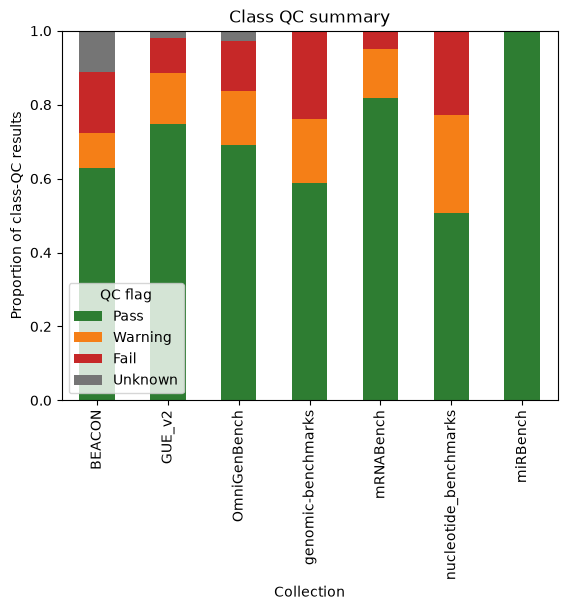

In [14]:
class_summary_plot = gbd.plot_qc_summary("class")


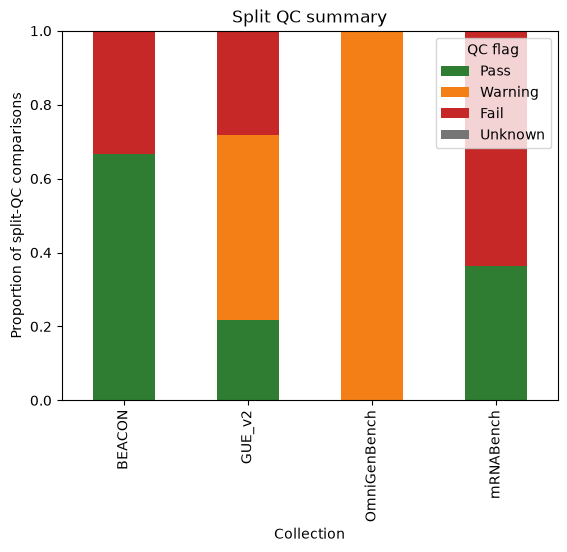

In [15]:
split_summary_plot = gbd.plot_qc_summary("split")


## Open self-contained QC reports

Run these cells locally to explore the interactive reports. Their large embedded HTML output is intentionally not stored in the repository notebooks.

In [16]:
class_report = gbd.get_class_qc_report(
    COLLECTION, DATASET, split="val", seq_col="seq"
)
display_qc_report(class_report)

In [17]:
split_report = gbd.get_split_qc_report(
    COLLECTION, DATASET, split_a="train", split_b="val"
)
display_qc_report(split_report)